# 02 · Exploratory Data Analysis & Geospatial Mapping

**Author:** Mohamed Ghassen Boughalmi

**Goal:** understand the cleaned dataset before modelling. *Where* is water stress, *how* has it changed since 2001,
*which* water uses drive it, and *how much* of the data is real observation versus estimate?

**Contents**
1. Data coverage & quality: how much can we trust each number?
2. The global picture: how stress is distributed and how it changed over time
3. World maps: stress tiers, an animated 2001–2023 map, sector mix, data freshness and 2035 risk
4. What drives stress: sector contributions in the most stressed countries
5. Biggest changes since the early 2000s
6. Correlations between the main variables
7. Key takeaways

Static maps are embedded below; **interactive versions (hover, zoom, year slider) are saved in `reports/maps/*.html`**.
Map-building code is in [`src/water_maps.py`](../src/water_maps.py) so the dashboard can reuse it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'src'))
import water_forecast as wf
import water_maps as wm

FIG_DIR = ROOT / 'reports' / 'figures'
MAP_DIR = ROOT / 'reports' / 'maps'
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
TIERS = [t for _, t in wf.STRESS_TIERS]
TIER_COLORS = [wm.TIER_COLORS[t] for t in TIERS]

master = pd.read_csv(ROOT / 'data' / 'processed' / 'Master_Global_Water_Dataset_2001_2023.csv')
latest = (master.dropna(subset=['Water_Stress_Total_Pct']).sort_values('Year').groupby('m49').tail(1))
print(f"{len(master):,} rows | {master['m49'].nunique()} countries | {master['Year'].min()}-{master['Year'].max()}")
print(f"Countries with a stress value: {latest['m49'].nunique()}")

4,181 rows | 183 countries | 2001-2023
Countries with a stress value: 178


## 1 · Data coverage & quality

Before drawing conclusions we check **how complete** each variable is and **how much of the stress data is a real
observation**. The UN marks every stress value as *Reported* by the country (A), *Estimated* (E) or *Imputed* (I),
and repeats the last value in years without new data.

In [2]:
key_cols = {
    'Water_Stress_Total_Pct': 'Water stress (SDG 6.4.2)',
    'Total_Withdrawal_FAO_10e9_m3': 'Total withdrawal (FAO)',
    'Agri_Withdrawal_10e9_m3': 'Agricultural withdrawal',
    'Ind_Withdrawal_10e9_m3': 'Industrial withdrawal',
    'Mun_Withdrawal_10e9_m3': 'Municipal withdrawal',
    'Freshwater_Abstracted_UNSD_10e9_m3': 'Freshwater abstracted (UNSD)',
    'Renewable_Freshwater_10e9_m3': 'Renewable freshwater (UNSD)',
}
completeness = pd.DataFrame({
    'Variable': key_cols.values(),
    'Rows_filled_pct': [round(100 * master[c].notna().mean(), 1) for c in key_cols],
    'Countries_with_any_value': [master.loc[master[c].notna(), 'm49'].nunique() for c in key_cols],
})
completeness

,Variable,Rows_filled_pct,Countries_with_any_value
0,Water stress (SDG 6.4.2),95.6,178
1,Total withdrawal (FAO),96.1,180
2,Agricultural withdrawal,95.8,180
3,Industrial withdrawal,95.6,180
4,Municipal withdrawal,97.8,183
5,Freshwater abstracted (UNSD),36.7,102
6,Renewable freshwater (UNSD),28.7,76


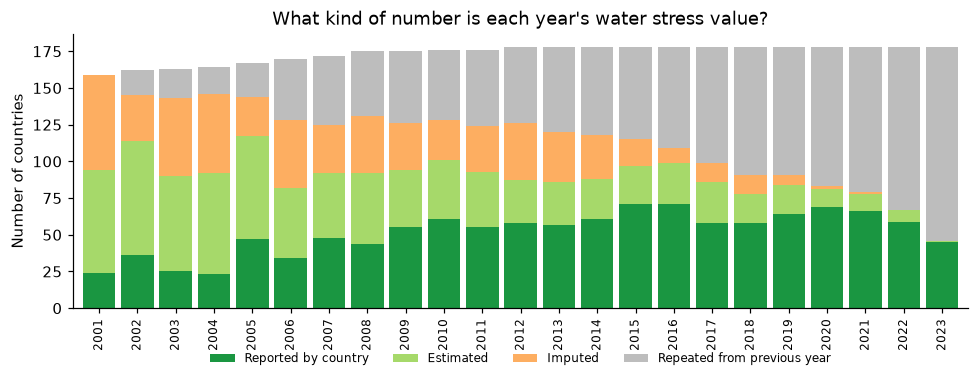

Share of all stress values:
Kind
Reported by country            29.8
Estimated                      21.3
Imputed                        15.1
Repeated from previous year    33.8


In [3]:
s = master.dropna(subset=['Water_Stress_Total_Pct']).copy()
s['Kind'] = np.where(s['Stress_Carried_Forward'], 'Repeated from previous year',
                     s['Stress_Obs_Status'].map({'A': 'Reported by country', 'E': 'Estimated', 'I': 'Imputed'}))
kinds = ['Reported by country', 'Estimated', 'Imputed', 'Repeated from previous year']
kind_colors = ['#1a9641', '#a6d96a', '#fdae61', '#bdbdbd']
by_year = s.groupby(['Year', 'Kind']).size().unstack().reindex(columns=kinds).fillna(0)

fig, ax = plt.subplots(figsize=(9, 3.6))
by_year.plot.bar(stacked=True, color=kind_colors, width=0.85, ax=ax)
ax.set(xlabel='', ylabel='Number of countries', title='What kind of number is each year\'s water stress value?')
ax.legend(frameon=False, fontsize=8, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.tick_params(axis='x', labelsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_01_data_quality_by_year.png', bbox_inches='tight'); plt.show()

share = s['Kind'].value_counts(normalize=True).reindex(kinds).mul(100).round(1)
print('Share of all stress values:'); print(share.to_string())

**Reading it:** renewable freshwater and abstraction from UNSD are sparse (under 40% of rows), so the analysis relies on
the **UN SDG 6.4.2 stress indicator and FAO withdrawals**, which cover almost every country-year. Even there, only a
minority of values are reported directly by countries; the rest are estimates, imputations or repeats. Trends must be
read with that in mind.

## 2 · The global picture

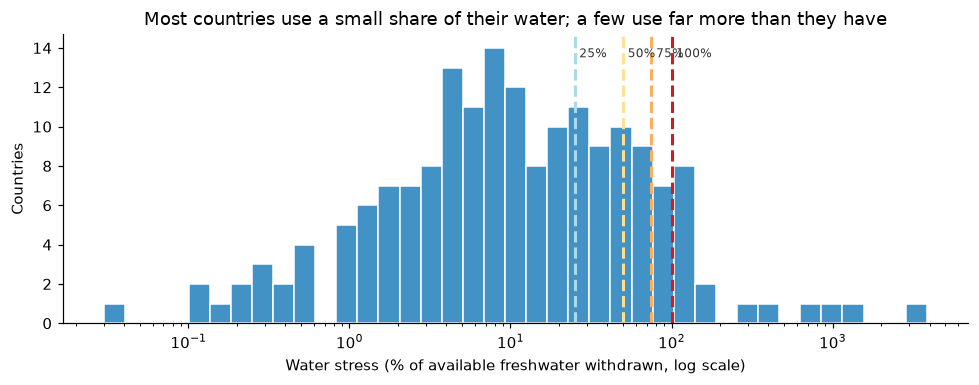

Water_Stress_Category
1. No Stress (<25%)           119
2. Low Stress (25-50%)         25
3. Medium Stress (50-75%)      11
4. High Stress (75-100%)        7
5. Critical Stress (>100%)     16

Median country: 10.1%   |   Max: Kuwait 3,850%


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
vals = latest['Water_Stress_Total_Pct'].clip(lower=0.01)
bins = np.logspace(np.log10(vals.min()), np.log10(vals.max()), 40)
ax.hist(vals, bins=bins, color='#4292c6', edgecolor='white')
ax.set_xscale('log')
for thr, col, lab in ((25, '#abd9e9', '25%'), (50, '#fee090', '50%'), (75, '#fdae61', '75%'), (100, '#d7191c', '100%')):
    ax.axvline(thr, color=col, lw=2, ls='--')
    ax.text(thr * 1.07, ax.get_ylim()[1] * 0.92, lab, color='#333', fontsize=8)
ax.set(xlabel='Water stress (% of available freshwater withdrawn, log scale)', ylabel='Countries',
       title='Most countries use a small share of their water; a few use far more than they have')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_02_stress_distribution.png'); plt.show()

tier_counts = latest['Water_Stress_Category'].value_counts().reindex(TIERS).fillna(0).astype(int)
print(tier_counts.to_string())
print(f"\nMedian country: {vals.median():.1f}%   |   Max: {latest.loc[vals.idxmax(), 'Country']} {vals.max():,.0f}%")

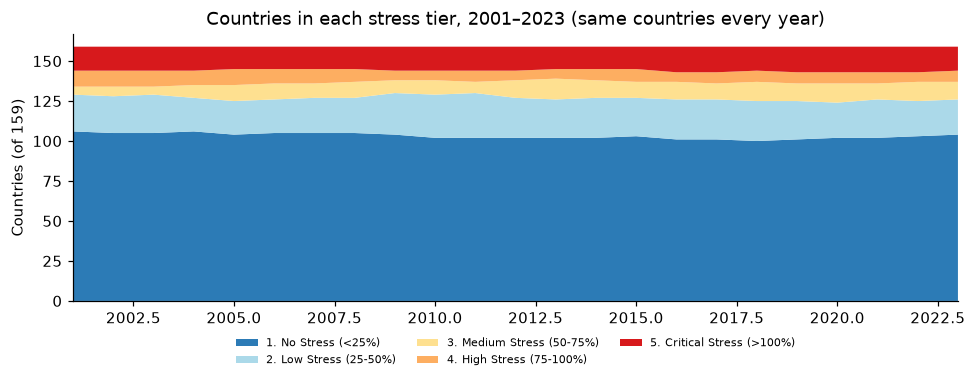

Water_Stress_Category  1. No Stress (<25%)  2. Low Stress (25-50%)  3. Medium Stress (50-75%)  4. High Stress (75-100%)  5. Critical Stress (>100%)
Year                                                                                                                                               
2001                                   106                      23                          5                        10                          15
2012                                   102                      25                         11                         6                          15
2023                                   104                      22                         11                         7                          15


In [5]:
# Balanced panel: only countries with a stress value in every year, so changes are real, not coverage effects
full = master.dropna(subset=['Water_Stress_Total_Pct']).groupby('m49')['Year'].nunique()
panel_ids = full[full == master['Year'].nunique()].index
panel = master[master['m49'].isin(panel_ids)]
comp = panel.groupby(['Year', 'Water_Stress_Category']).size().unstack().reindex(columns=TIERS).fillna(0)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.stackplot(comp.index, comp.T.to_numpy(), colors=TIER_COLORS, labels=TIERS)
ax.set(xlim=(comp.index.min(), comp.index.max()), ylabel=f'Countries (of {len(panel_ids)})',
       title='Countries in each stress tier, 2001–2023 (same countries every year)')
ax.legend(frameon=False, fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_03_tiers_over_time.png', bbox_inches='tight'); plt.show()

print(comp.loc[[2001, 2012, 2023]].astype(int).to_string())

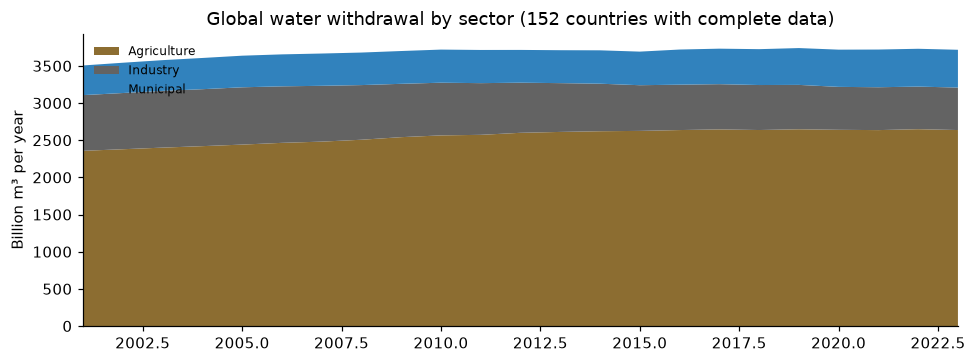

Total withdrawal 3,506 -> 3,717 billion m³ (+6.0%)
      Agri %  Ind %  Mun %
Year                      
2001    67.2   21.4   11.4
2023    70.9   15.4   13.7


In [6]:
# Global withdrawals by sector (same balanced idea: countries with all three sectors every year)
sec = master.dropna(subset=['Agri_Withdrawal_10e9_m3', 'Ind_Withdrawal_10e9_m3', 'Mun_Withdrawal_10e9_m3'])
yrs = sec.groupby('m49')['Year'].nunique()
sec = sec[sec['m49'].isin(yrs[yrs == master['Year'].nunique()].index)]
tot = sec.groupby('Year')[['Agri_Withdrawal_10e9_m3', 'Ind_Withdrawal_10e9_m3', 'Mun_Withdrawal_10e9_m3']].sum()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.stackplot(tot.index, tot.T.to_numpy(), colors=['#8c6d31', '#636363', '#3182bd'],
             labels=['Agriculture', 'Industry', 'Municipal'])
ax.set(xlim=(tot.index.min(), tot.index.max()), ylabel='Billion m³ per year',
       title=f'Global water withdrawal by sector ({sec["m49"].nunique()} countries with complete data)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_04_global_withdrawal_by_sector.png'); plt.show()

shares = tot.div(tot.sum(axis=1), axis=0).mul(100).round(1)
print(f"Total withdrawal {tot.sum(axis=1).iloc[0]:,.0f} -> {tot.sum(axis=1).iloc[-1]:,.0f} billion m³ "
      f"({100 * (tot.sum(axis=1).iloc[-1] / tot.sum(axis=1).iloc[0] - 1):+.1f}%)")
print(shares.loc[[2001, 2023]].rename(columns=lambda c: c.split('_')[0] + ' %').to_string())

## 3 · World maps

Each map is saved as an **interactive HTML** (hover for values, zoom, and for the animated map a year slider) and a
static PNG shown here.

### 3.1 Water stress today

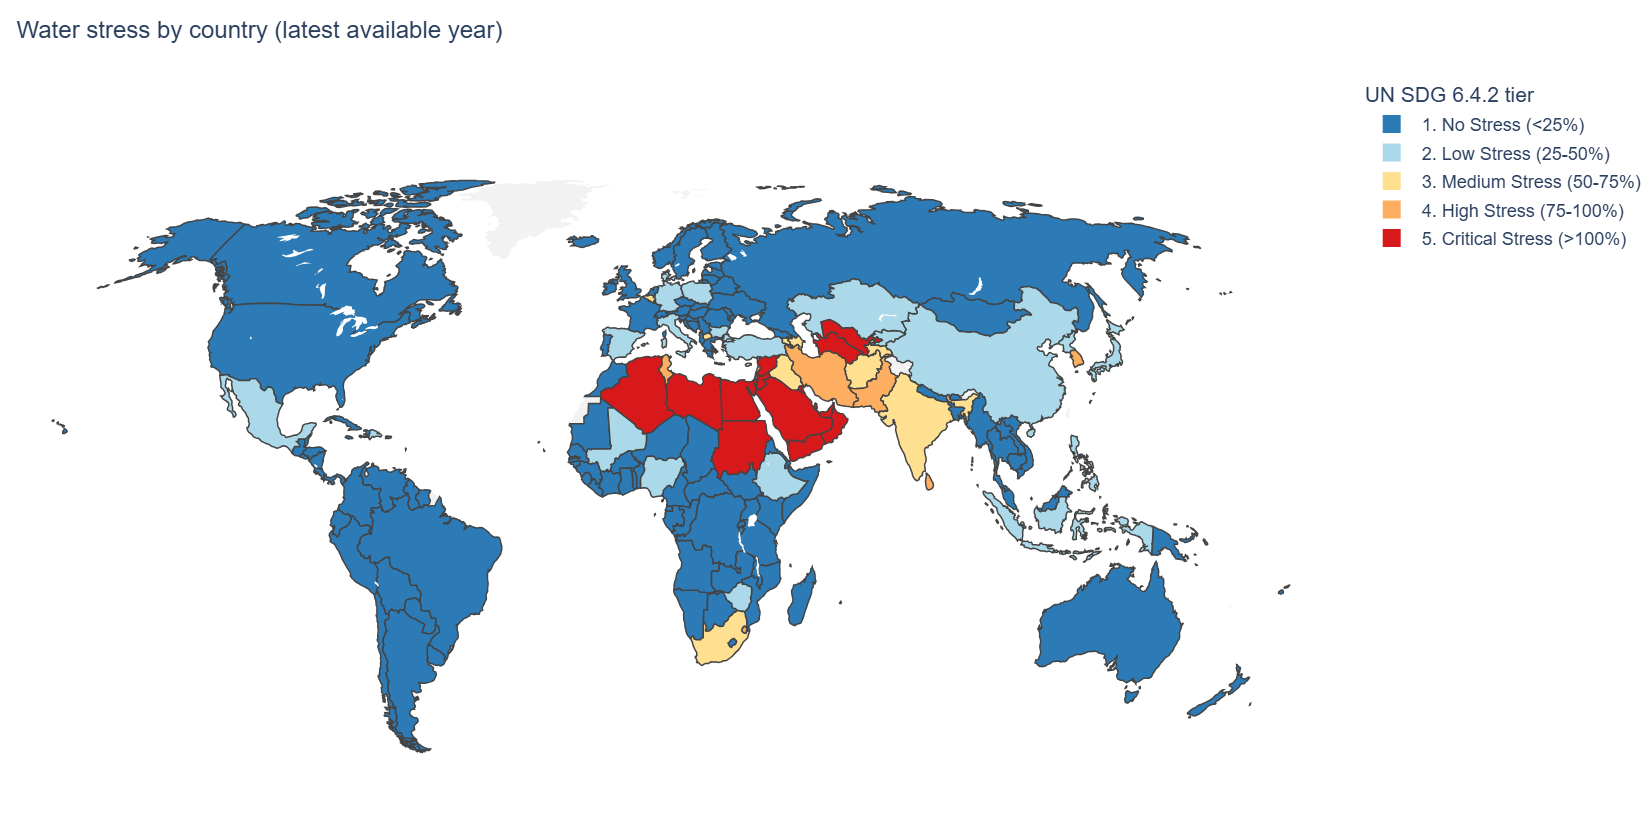

In [7]:
fig = wm.stress_tier_map(master)
display(Image(wm.save_map(fig, MAP_DIR, 'map_01_stress_latest')))

### 3.2 How the map changed, 2001–2023 (animated)

The animation is interactive only. Open **`reports/maps/map_02_stress_animation.html`** in a browser and press ▶.
Below: the first and last year side by side.

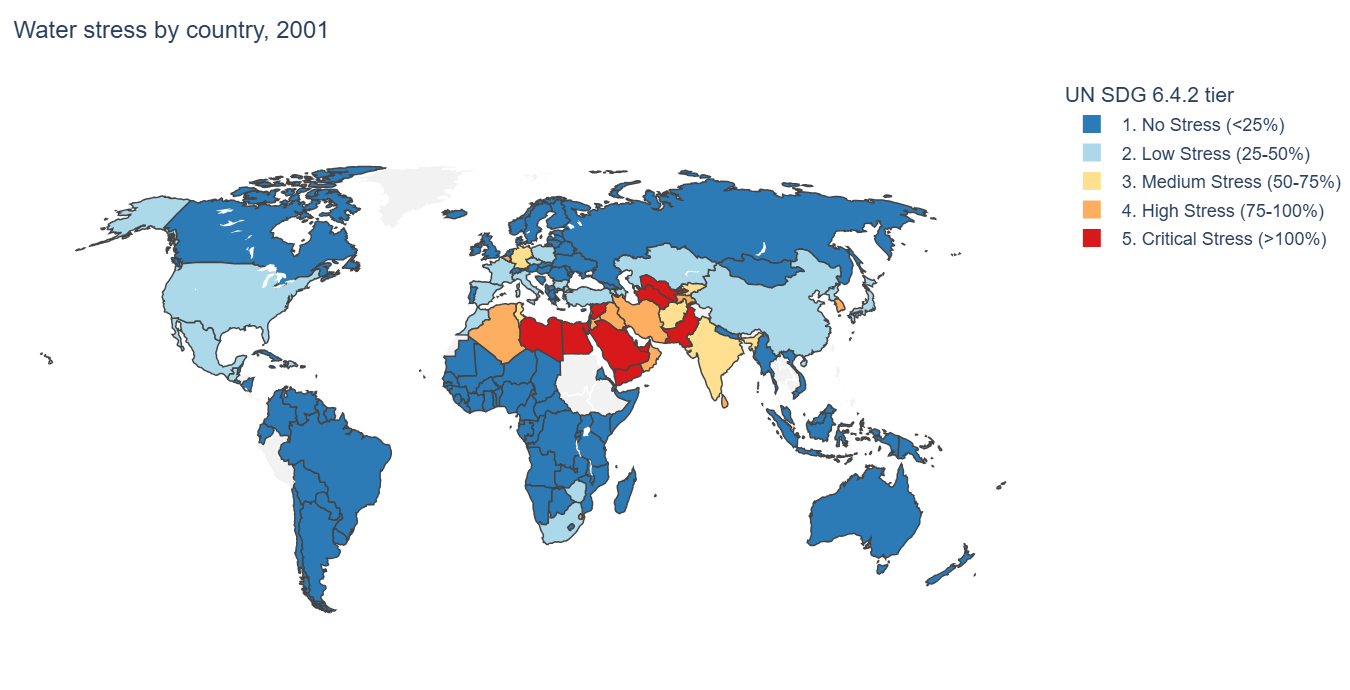

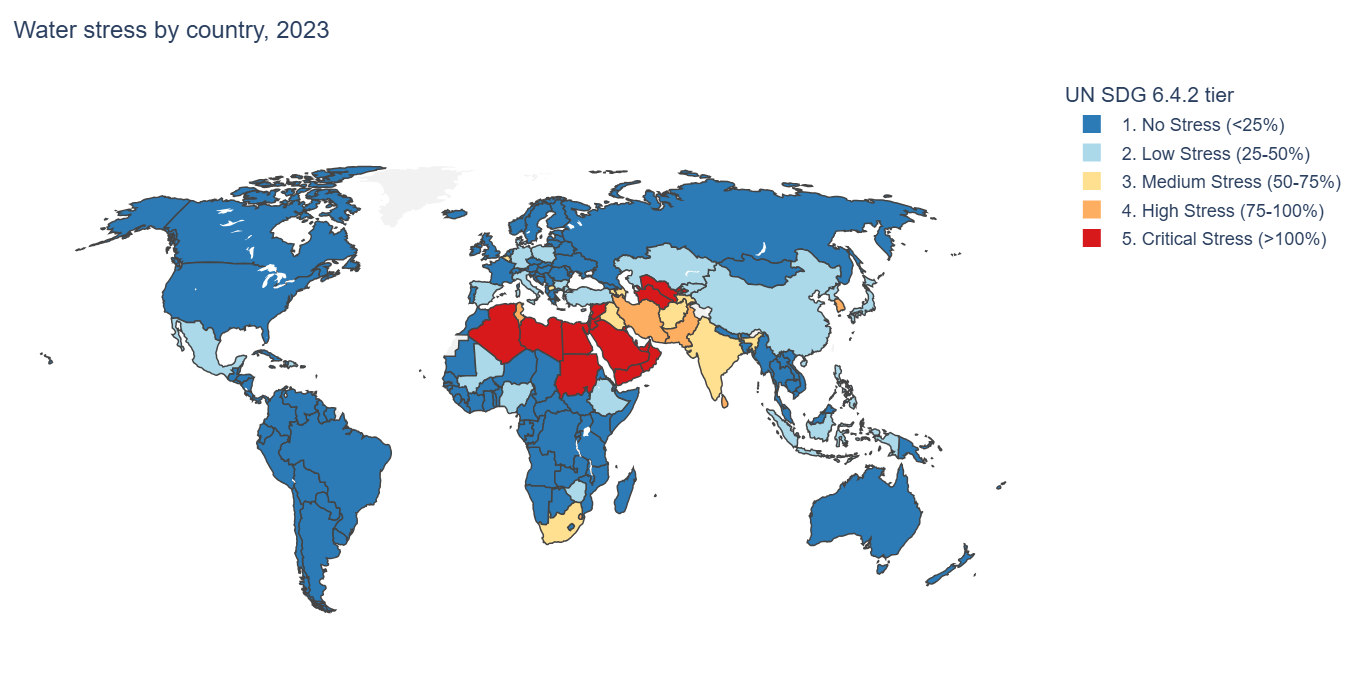

In [8]:
anim = wm.stress_tier_animation(master)
anim.write_html(MAP_DIR / 'map_02_stress_animation.html', include_plotlyjs='cdn')
for y in (2001, 2023):
    display(Image(wm.save_map(wm.stress_tier_map(master, year=y), MAP_DIR, f'map_02_stress_{y}', width=900, height=460)))

### 3.3 Which sector uses the most water?

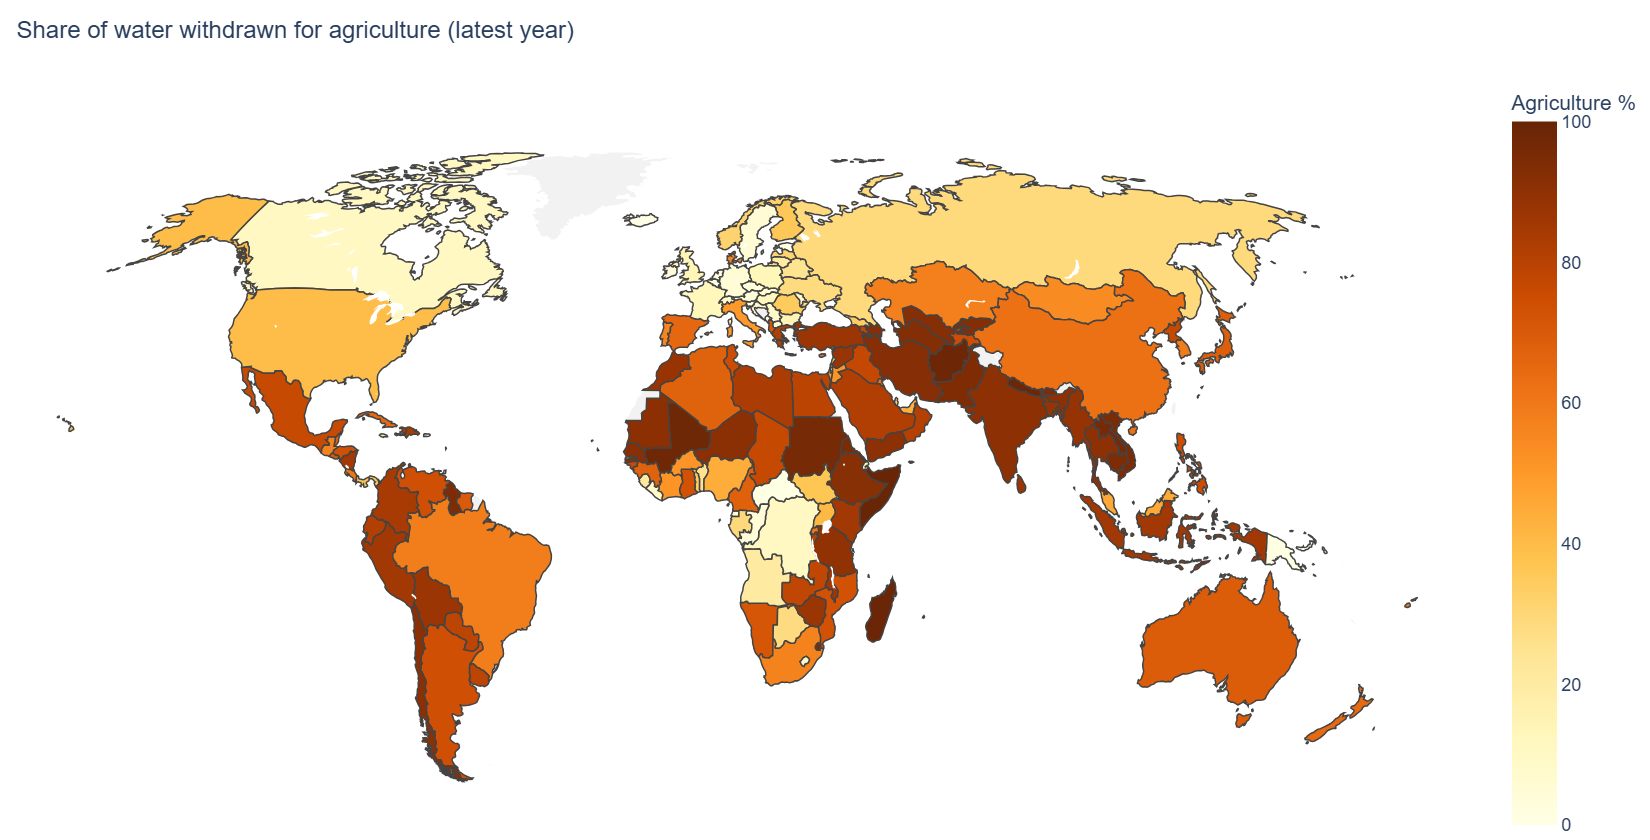

Dominant_Sector
Agriculture    107
Municipal       45
Industry        27


In [9]:
lat_sec = (master.dropna(subset=['Agri_Share_Pct', 'Ind_Share_Pct', 'Mun_Share_Pct'])
           .sort_values('Year').groupby('m49').tail(1).copy())
fig = wm.continuous_map(
    lat_sec, 'Agri_Share_Pct', 'Share of water withdrawn for agriculture (latest year)', 'Agriculture %',
    scale='YlOrBr', range_color=(0, 100),
    hover={'Ind_Share_Pct': ':.1f', 'Mun_Share_Pct': ':.1f', 'Year': True})
display(Image(wm.save_map(fig, MAP_DIR, 'map_03_agri_share')))

lat_sec['Dominant_Sector'] = lat_sec[['Agri_Share_Pct', 'Ind_Share_Pct', 'Mun_Share_Pct']].idxmax(axis=1).map(
    {'Agri_Share_Pct': 'Agriculture', 'Ind_Share_Pct': 'Industry', 'Mun_Share_Pct': 'Municipal'})
print(lat_sec['Dominant_Sector'].value_counts().to_string())

### 3.4 How fresh is the data?

Year of each country's most recent **genuine** stress observation (not a repeat). Old data means the
"current" value on the other maps may be out of date.

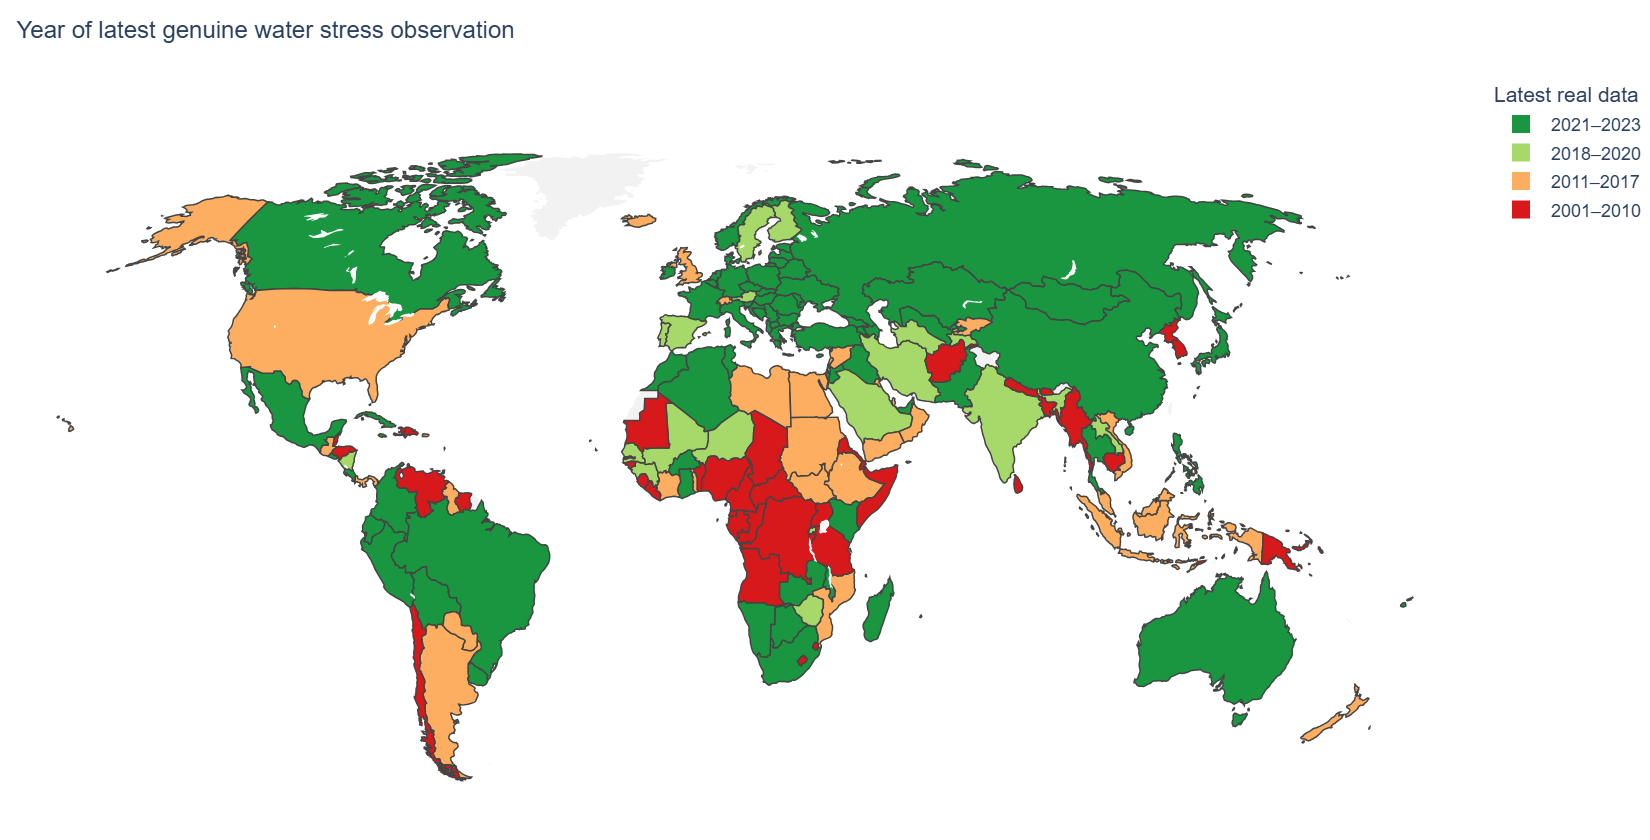

Data_Freshness
2021–2023    80
2018–2020    18
2011–2017    34
2001–2010    46


In [10]:
real = master[master['Water_Stress_Total_Pct'].notna() & ~master['Stress_Carried_Forward']]
fresh = real.sort_values('Year').groupby('m49').tail(1)[['ISO3_Code', 'Country', 'Year', 'Stress_Obs_Status']]
fresh['Data_Freshness'] = pd.cut(fresh['Year'], [2000, 2010, 2017, 2020, 2023],
                                 labels=['2001–2010', '2011–2017', '2018–2020', '2021–2023']).astype(str)
fresh_colors = {'2021–2023': '#1a9641', '2018–2020': '#a6d96a', '2011–2017': '#fdae61', '2001–2010': '#d7191c'}
fig = wm.categorical_map(fresh, 'Data_Freshness', 'Year of latest genuine water stress observation',
                         fresh_colors, list(fresh_colors), 'Latest real data', hover={'Year': True})
display(Image(wm.save_map(fig, MAP_DIR, 'map_04_data_freshness')))
print(fresh['Data_Freshness'].value_counts().reindex(list(fresh_colors)).to_string())

### 3.5 Risk of Critical water stress by 2035

Combines today's status with the forecast from `03_forecast_water_stress.ipynb`: the probability that a country's
stress exceeds 100% in 2035 under the back-tested base model. *(Run notebook 03 first; this map reads its output.)*

Uncertainty scale recovered from forecast file: s = 0.1335


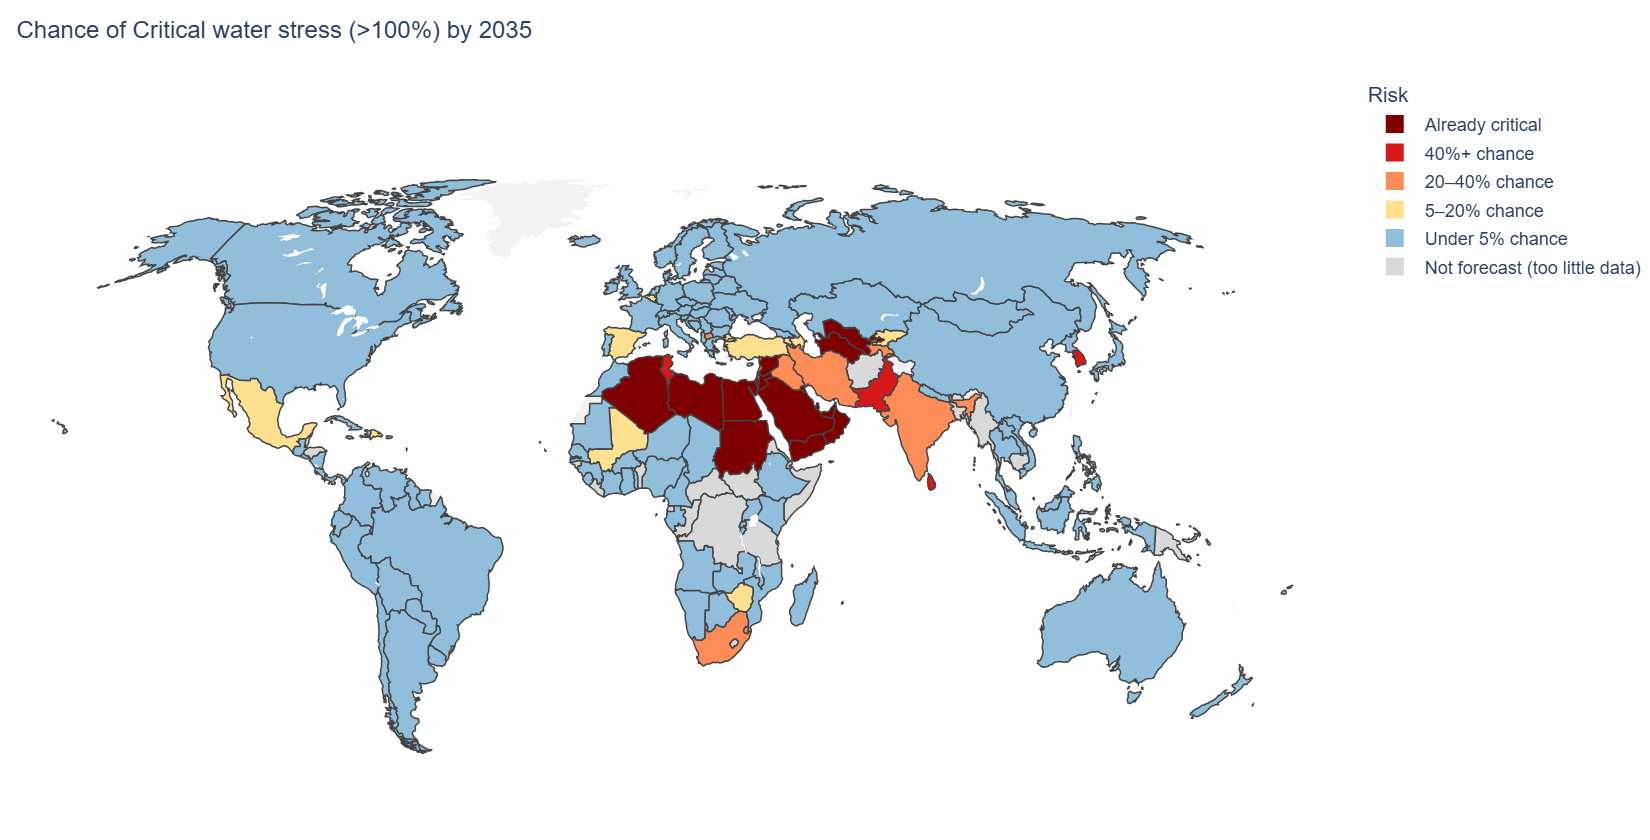

Risk_2035
Already critical                   16
40%+ chance                         4
20–40% chance                       8
5–20% chance                       11
Under 5% chance                   113
Not forecast (too little data)     26


In [11]:
fc_path = ROOT / 'data' / 'processed' / 'Water_Stress_Forecast_2024_2035.csv'
if fc_path.exists():
    fc = pd.read_csv(fc_path)
    f35 = fc[fc['Year'] == 2035].copy()
    # Recover the calibrated uncertainty scale s saved in the 80% band:
    # ln((1 + Upper) / (1 + Forecast)) = 1.2816 * s * sqrt(h)   (same s for every country)
    h = 2035 - f35['Last_Observed_Year']
    s_each = (np.log1p(f35['Upper_80_Pct']) - np.log1p(f35['Forecast_Stress_Pct'])) / (1.2816 * np.sqrt(h))
    s_scale = float(s_each.median())
    print(f'Uncertainty scale recovered from forecast file: s = {s_scale:.4f}')
    f35['Chance_Critical_2035'] = [wf.chance_above(f, 100, s_scale, hh) for f, hh in zip(f35['Forecast_Stress_Pct'], h)]

    risk = latest[['m49', 'ISO3_Code', 'Country', 'Water_Stress_Total_Pct']].merge(
        f35[['m49', 'Chance_Critical_2035', 'Forecast_Stress_Pct', 'Last_Observed_Year']], on='m49', how='left')
    def risk_band(r):
        if r['Water_Stress_Total_Pct'] >= 100: return 'Already critical'
        if pd.isna(r['Chance_Critical_2035']): return 'Not forecast (too little data)'
        if r['Chance_Critical_2035'] >= 40: return '40%+ chance'
        if r['Chance_Critical_2035'] >= 20: return '20–40% chance'
        if r['Chance_Critical_2035'] >= 5: return '5–20% chance'
        return 'Under 5% chance'
    risk['Risk_2035'] = risk.apply(risk_band, axis=1)
    risk['Chance_%'] = risk['Chance_Critical_2035'].round(0)
    risk_colors = {'Already critical': '#7f0000', '40%+ chance': '#d7191c', '20–40% chance': '#fc8d59',
                   '5–20% chance': '#fee090', 'Under 5% chance': '#91bfdb', 'Not forecast (too little data)': '#d9d9d9'}
    fig = wm.categorical_map(risk, 'Risk_2035', 'Chance of Critical water stress (>100%) by 2035',
                             risk_colors, list(risk_colors), 'Risk',
                             hover={'Water_Stress_Total_Pct': ':.1f', 'Chance_%': True, 'Last_Observed_Year': True})
    display(Image(wm.save_map(fig, MAP_DIR, 'map_05_critical_risk_2035')))
    print(risk['Risk_2035'].value_counts().reindex(list(risk_colors)).fillna(0).astype(int).to_string())
else:
    print('Forecast file not found. Run notebooks/03_forecast_water_stress.ipynb first.')

## 4 · What drives stress in the most stressed countries?

The UN splits each country's stress into the part caused by **agriculture**, **industry** and **services/municipal** use.

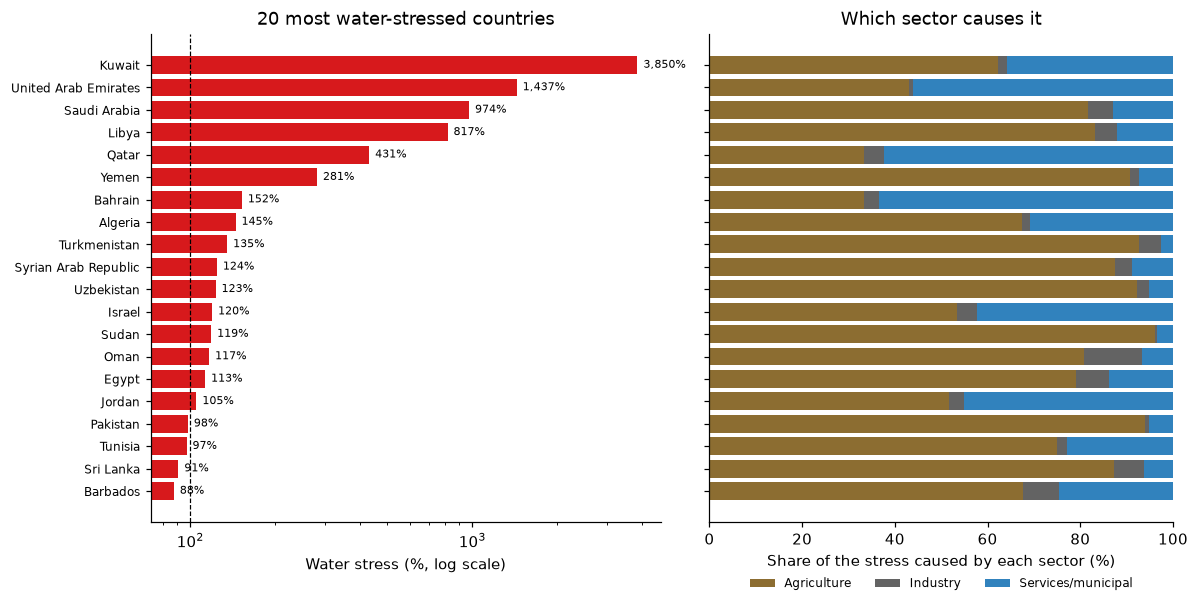

Agriculture causes the majority of stress in 17 of these 20 countries; median agricultural share 80%.


In [12]:
contrib_cols = ['Water_Stress_Agri_Pct', 'Water_Stress_Ind_Pct', 'Water_Stress_Services_Pct']
top = (master.dropna(subset=contrib_cols + ['Water_Stress_Total_Pct']).sort_values('Year')
       .groupby('m49').tail(1).nlargest(20, 'Water_Stress_Total_Pct').iloc[::-1])
share_top = top[contrib_cols].div(top[contrib_cols].sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True, gridspec_kw={'width_ratios': [1.1, 1]})
ax1.barh(top['Country'], top['Water_Stress_Total_Pct'], color='#d7191c')
ax1.set_xscale('log'); ax1.axvline(100, color='black', lw=0.8, ls='--')
ax1.set(xlabel='Water stress (%, log scale)', title='20 most water-stressed countries')
for y, v in enumerate(top['Water_Stress_Total_Pct']):
    ax1.text(v * 1.05, y, f'{v:,.0f}%', va='center', fontsize=7)
left = np.zeros(len(top))
for col, c, lab in zip(contrib_cols, ['#8c6d31', '#636363', '#3182bd'], ['Agriculture', 'Industry', 'Services/municipal']):
    ax2.barh(top['Country'], share_top[col], left=left, color=c, label=lab); left += share_top[col].to_numpy()
ax2.set(xlabel='Share of the stress caused by each sector (%)', xlim=(0, 100), title='Which sector causes it')
ax2.legend(frameon=False, fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.09))
ax1.tick_params(axis='y', labelsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_05_top20_sector_drivers.png', bbox_inches='tight'); plt.show()

print(f"Agriculture causes the majority of stress in {(share_top['Water_Stress_Agri_Pct'] > 50).sum()} of these 20 countries; "
      f"median agricultural share {share_top['Water_Stress_Agri_Pct'].median():.0f}%.")

## 5 · Biggest changes since the early 2000s

Compares each country's **first genuine observation (2001–2005)** with its **latest genuine observation (2018–2023)**,
so both ends are real data rather than repeats.

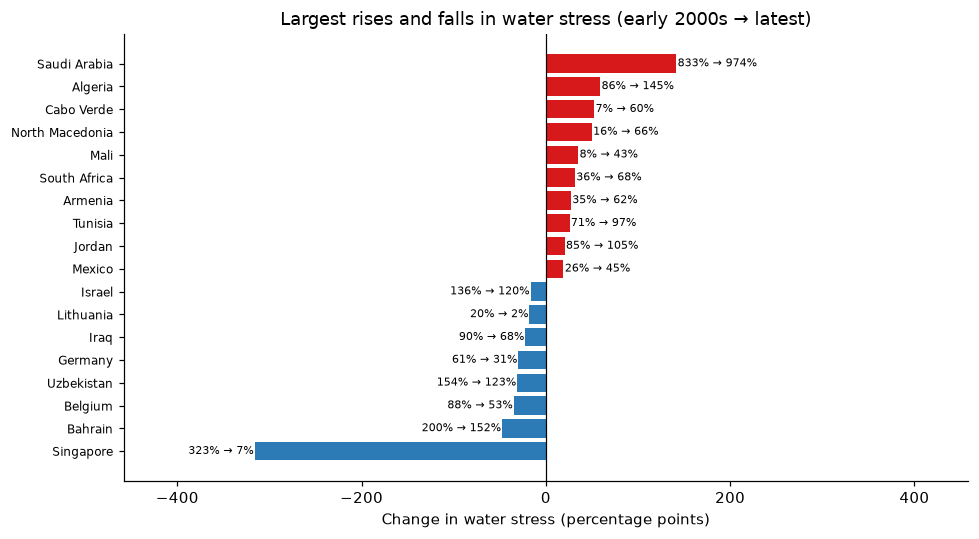

Note: Singapore's fall is most likely a change in how its water resources are counted, not a real change.
Compared 93 countries: 44 rose, 49 fell; median change -0.34 pp


In [13]:
early = real[real['Year'] <= 2005].sort_values('Year').groupby('m49').head(1)
late = real[real['Year'] >= 2018].sort_values('Year').groupby('m49').tail(1)
chg = early[['m49', 'Country', 'Year', 'Water_Stress_Total_Pct']].merge(
    late[['m49', 'Year', 'Water_Stress_Total_Pct']], on='m49', suffixes=('_start', '_end'))
chg = chg[chg['Water_Stress_Total_Pct_end'] < 1000]   # Gulf outliers would squash the chart
chg['Change_pp'] = chg['Water_Stress_Total_Pct_end'] - chg['Water_Stress_Total_Pct_start']
movers = pd.concat([chg.nsmallest(8, 'Change_pp'), chg.nlargest(10, 'Change_pp')]).drop_duplicates('m49')
movers = movers.sort_values('Change_pp')

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(movers['Country'], movers['Change_pp'], color=np.where(movers['Change_pp'] > 0, '#d7191c', '#2c7bb6'))
for y, (v, a, b) in enumerate(zip(movers['Change_pp'], movers['Water_Stress_Total_Pct_start'], movers['Water_Stress_Total_Pct_end'])):
    ax.text(v + (1.5 if v > 0 else -1.5), y, f'{a:.0f}% → {b:.0f}%', va='center', ha='left' if v > 0 else 'right', fontsize=7)
ax.axvline(0, color='black', lw=0.8)
ax.set(xlabel='Change in water stress (percentage points)', title='Largest rises and falls in water stress (early 2000s → latest)')
ax.tick_params(axis='y', labelsize=8)
xmax = movers['Change_pp'].abs().max() * 1.45
ax.set_xlim(-xmax, xmax)
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_06_biggest_changes.png'); plt.show()

print("Note: Singapore's fall is most likely a change in how its water resources are counted, not a real change.")
print(f"Compared {len(chg)} countries: {(chg['Change_pp'] > 0).sum()} rose, {(chg['Change_pp'] < 0).sum()} fell; "
      f"median change {chg['Change_pp'].median():+.2f} pp")

## 6 · Correlations between the main variables

Spearman rank correlation (robust to the huge outliers) on each country's latest complete year.

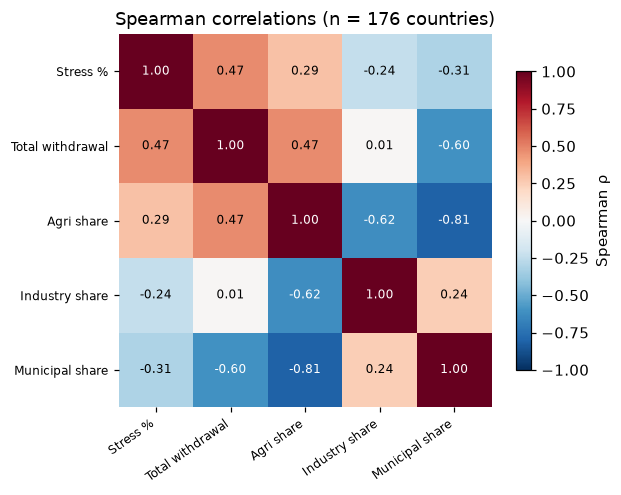

,Stress %,Total withdrawal,Agri share,Industry share,Municipal share
Stress %,1.00,0.47,0.29,-0.24,-0.31
Total withdrawal,0.47,1.00,0.47,0.01,-0.60
Agri share,0.29,0.47,1.00,-0.62,-0.81
Industry share,-0.24,0.01,-0.62,1.00,0.24
Municipal share,-0.31,-0.60,-0.81,0.24,1.00


In [14]:
corr_cols = {'Water_Stress_Total_Pct': 'Stress %', 'Total_Withdrawal_FAO_10e9_m3': 'Total withdrawal',
             'Agri_Share_Pct': 'Agri share', 'Ind_Share_Pct': 'Industry share', 'Mun_Share_Pct': 'Municipal share'}
cx = master.dropna(subset=list(corr_cols)).sort_values('Year').groupby('m49').tail(1)[list(corr_cols)].rename(columns=corr_cols)
corr = cx.corr(method='spearman')

fig, ax = plt.subplots(figsize=(5.8, 4.6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha='right', fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr.iloc[i, j]) > 0.5 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8, label='Spearman ρ')
ax.set_title(f'Spearman correlations (n = {len(cx)} countries)')
ax.spines[:].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_07_correlations.png'); plt.show()
corr.round(2)

## 7 · Key takeaways

1. **Most of the data is not a fresh measurement.** Only ~30% of stress values are reported directly by countries;
   ~34% simply repeat the previous year, and for 46 countries the latest real observation is from 2010 or earlier
   (map 3.4). Every conclusion, and the forecast, must be read with this in mind.
2. **Water stress is extremely unequal.** The median country withdraws ~10% of its available water, but 16 countries
   withdraw more than 100%, led by Kuwait (~3,850%), the UAE (~1,440%) and Saudi Arabia (~970%).
3. **The crisis is geographically concentrated.** Critical stress forms one continuous belt across **North Africa,
   the Arabian Peninsula and Central Asia** (map 3.1); High/Medium stress surrounds it (Iran, Pakistan, India, Tunisia).
4. **The picture changes slowly.** Following the same countries every year, the number in each tier barely moved
   between 2001 and 2023 (e.g. 15 Critical in both years). This is why "no change" is a strong forecasting baseline.
5. **Agriculture is the main driver.** Agriculture is the largest water user in 107 of 179 countries; global withdrawals
   grew ~6% from 2001 to 2023 and agriculture's share rose from 67% to 71%. In 17 of the 20 most stressed countries
   agriculture causes most of the stress. The exceptions are Gulf states (UAE, Qatar, Bahrain), where municipal use dominates.
6. **Movement in both directions.** Of 93 countries with real data at both ends, 44 became more stressed and 49 less.
   The largest rises were in Saudi Arabia, Algeria, Cabo Verde, North Macedonia and Mali.
7. **Who is next?** Countries with the highest chance of reaching Critical by 2035 (Tunisia, Pakistan, Sri Lanka,
   Republic of Korea) mostly border the existing critical belt (map 3.5).
8. **Correlations are moderate.** Stress rises with total withdrawal (ρ ≈ 0.47) and agricultural share (ρ ≈ 0.29) and
   falls with municipal share (ρ ≈ −0.31). These are associations across countries, not causes.

In [15]:
print('Figures:', sorted(p.name for p in FIG_DIR.glob('eda_*.png')))
print('Maps   :', sorted(p.name for p in MAP_DIR.glob('*.html')))

Figures: ['eda_01_data_quality_by_year.png', 'eda_02_stress_distribution.png', 'eda_03_tiers_over_time.png', 'eda_04_global_withdrawal_by_sector.png', 'eda_05_top20_sector_drivers.png', 'eda_06_biggest_changes.png', 'eda_07_correlations.png']
Maps   : ['map_01_stress_latest.html', 'map_02_stress_2001.html', 'map_02_stress_2023.html', 'map_02_stress_animation.html', 'map_03_agri_share.html', 'map_04_data_freshness.html', 'map_05_critical_risk_2035.html']
